In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**Optimization of solar panel tilt angle plus temperatures and winds effect on energy production in Sofia, Bulgaria**

**A numerical study based on solar radiation and weather data for 2023**

**Abstract.** 

Solar energy is becoming an increasingly important source of electricity around the world, solar panels are widely used in private homes, businesses, and large solar power plants. However, the amount of electricity produced by a solar panel depends on several factors, including its position, the amount of sunlight, air temperature, and wind speed.

The aim of this project is to find a suitable tilt angel for a solar panel installed in Sofia, Bulgaria. The study also quantifies how panel temperature and wind speed can affect its energy production.

The project uses solar radiation and weather data for Sofia for the year 2023.I compare 3 scenarios: a model with constant panel efficiency, a model that takes panel temperature into account using the NOCT method, and a model based on the Faiman temperature model, which also considers wind speed.
The results are used to find the tilt angle that gives the highest estimated annual energy production.I also compares how much energy production changes when temperature and wind effects are included in the calculations.



**Introduction.**

The use of solar panels is growing in many countries because solar power is a renewable source of energy and can help reduce the use of fossil fuels. However, the amount of electricity produced by a solar panel depends not only on the amount of sunlight it receives. The position and tilt angle of the panel, air temperature, and wind speed can also have a significant effect on its performance.
One important problem is that solar panels become hot when they receive strong sunlight. As the panel temperature increases, its electrical efficiency usually decreases. This means that a panel may receive a large amount of solar energy but still produce less electricity than expected. Wind can help cool the panel and reduce its operating temperature. Therefore, wind speed can also influence the amount of electricity produced.
The tilt angle is another important factor. A solar panel receives the most direct sunlight when the sun rays reach its surface at a suitable angle. The best fixed tilt angle depends on the geographical location and local weather conditions. 
The aim of this project is to investigate these factors for Sofia, Bulgaria. The study will examine whether changing the fixed tilt angle of a solar panel can increase its estimated annual energy production. It will also investigate how panel temperature and wind speed affect the results, and whether the choice of tilt angle remains the same when these effects are included.
The calculations are based on solar radiation and weather data for Sofia for the year 2023. The data is obtained from the European Commission Photovoltaic Geographical Information System (PVGIS). This system provides information about solar radiation and weather conditions for different geographical locations.
First, the solar energy received by a panel will be estimated for different tilt angles. Then, three calculation scenarios will be compared. The first scenario will assume constant panel efficiency. The second will include the effect of temperature using the Nominal Operating Cell Temperature (NOCT) method. The third will use the Faiman model, which estimates panel temperature based on solar radiation, air temperature, and wind speed.
The effect of panel orientation, tilt angle, temperature, and wind on solar energy production has already been studied in solar energy research. This project applies these established ideas to a specific location and a particular year. Its purpose is to compare the results under local conditions and to understand how much temperature and wind can change the estimated energy production.
The final results will help identify a suitable fixed tilt angle for a solar panel in Sofia and show whether taking temperature and wind into account changes the estimated annual energy production.


**Part. 1. Parameters, data and time intervals.**

My project studies a fixed solar panel installed in Sofia, Bulgaria. I use the following panel parameters:
  Panel area: 1.6 m². This is the surface area of the solar panel.
  Nominal efficiency: 20%. This is the electrical efficiency under standard conditions.
  Ground albedo: 0.20. This means that I assume the ground reflects 20% of the incoming solar radiation.
  NOCT: 45°C. This value is used to estimate the operating temperature of the panel.
  Temperature coefficient: 0.004 per °C. This means that the panel efficiency decreases by approximately   0.4% of its nominal value for each degree above 25°C.


For the Faiman temperature model, I use two additional coefficients:

U0 = 25

U1 = 6.84

These coefficients describe how the panel loses heat to the surrounding air and wind.
I will test tilt angles from 0° to 90° with a step of 0.5°. The panel is assumed to face south.

In [2]:
# Coordinates and parameters
latitude = 42.6965
longitude = 23.3220
panel_area = 1.6
nominal_efficiency = 0.20
ground_albedo = 0.20
NOCT = 45
temperature_coefficient = 0.004
U0 = 25
U1 = 6.84

# Tilt angle range
tilt_angles = np.arange(0, 90.5, 0.5)
print("Number of tested tilt angles:", len(tilt_angles))

Number of tested tilt angles: 181


The data is stored in a CSV file called `sofia_solar_data_2023.csv`.It was obtained from the Photovoltaic Geographical Information System (PVGIS) for Sofia, Bulgaria, for the year 2023.

The file contains the following columns:

`time` - date and time of the measurement.
`P` - photovoltaic power output provided by PVGIS.
`Gb(i)` - direct solar radiation on the selected surface.
`Gd(i)` - diffuse solar radiation on the selected surface.
`Gr(i)` - reflected solar radiation on the selected surface.
`H_sun` - sun height above the horizon.
`T2m` - air temperature at 2 metres above the ground.
`WS10m` - wind speed at 10 metres above the ground.
`Int` - information about the time interval.

In my PVGIS request, the surface slope was set to 0 degrees. This means that the radiation data was requested for a horizontal surface.

Once the data is uploaded and before further calculations, I check that it is loaded correctly (number of measurements, columns, missing values) and its type by displaying the first rows.

In [3]:
# Data upload
file_path = "sofia_solar_data_2023.csv"
with open(file_path, "r", encoding="utf-8-sig") as file:
    lines = file.readlines()

header_row = None

for i, line in enumerate(lines):
    if "time" in line.lower() and "t2m" in line.lower():
        header_row = i
        break

if header_row is None:
    raise ValueError("Could not find the data header in the CSV file.")
data = pd.read_csv(
    file_path,
    skiprows=header_row,
    sep=None,
    engine="python"
)
data.columns = data.columns.str.strip()

# Convert numerical columns to numeric values
numeric_columns = [
    "P", "Gb(i)", "Gd(i)", "Gr(i)",
    "H_sun", "T2m", "WS10m"
]

for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")
    # Check the loaded dataset

print("Number of measurements:", len(data))
print("Number of columns:", len(data.columns))
print("Missing values:", data.isnull().sum().sum())

Number of measurements: 8760
Number of columns: 9
Missing values: 0


In [4]:
# Show the first five rows
display(data.head())

# Show column names
print("Column names:")
print(data.columns.tolist())

# Show information about the data
data.info()

,time,P,Gb(i),Gd(i),Gr(i),H_sun,T2m,WS10m,Int
0,20230101:0010,0.0,0.0,0.0,0,0.0,0.36,1.38,0
1,20230101:0110,0.0,0.0,0.0,0,0.0,0.05,1.45,0
2,20230101:0210,0.0,0.0,0.0,0,0.0,0.01,1.38,0
3,20230101:0310,0.0,0.0,0.0,0,0.0,0.02,1.38,0
4,20230101:0410,0.0,0.0,0.0,0,0.0,-0.22,1.45,0


Column names:
['time', 'P', 'Gb(i)', 'Gd(i)', 'Gr(i)', 'H_sun', 'T2m', 'WS10m', 'Int']
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    8760 non-null   str    
 1   P       8760 non-null   float64
 2   Gb(i)   8760 non-null   float64
 3   Gd(i)   8760 non-null   float64
 4   Gr(i)   8760 non-null   int64  
 5   H_sun   8760 non-null   float64
 6   T2m     8760 non-null   float64
 7   WS10m   8760 non-null   float64
 8   Int     8760 non-null   int64  
dtypes: float64(6), int64(2), str(1)
memory usage: 727.3 KB


The expected number of hours in a normal year: 365 days × 24 hours = 8760 hours.( 8760 rows, exactly in the file). I'l convert the time column into a date and time format that Python can understand. Then I will check the time difference between measurements and confirm that the data covers the whole 2023 year.

The time interval is the difference between two consecutive measurements.

I calculate it as:

$$ \Delta t_i = t_{i+1} - t_i $$

Where:

$\Delta t_i$ is the time interval between two measurements;

$ t_i $ is the time of the current measurement;

$ t_{i+1} $ is the time of the next measurement.


In my dataset, the expected time interval is:

$$ \Delta t = 1 \text{ hour} $$


In [5]:
data["time"] = pd.to_datetime(
    data["time"],
    format="%Y%m%d:%H%M"
)
time_intervals = data["time"].diff().dropna()
interval_hours = time_intervals.dt.total_seconds() / 3600
# Set the time interval in hours
dt_hours = 1.0
#Show the first and last measurements
print("First measurement:", data["time"].iloc[0])
print("Last measurement:", data["time"].iloc[-1])

First measurement: 2023-01-01 00:10:00
Last measurement: 2023-12-31 23:10:00


The relationship between power and energy is:

$E = P \cdot \Delta t$

Where:

$E$ is energy in Wh;
$P$ is power in W;
$\Delta t$ is the time interval in hours.

For my solar panel, I estimate electrical energy using solar radiation, panel area, and electrical efficiency:

$E_i = G_i \cdot A \cdot \eta_i \cdot \Delta t$

Where:

$E_i$ is electrical energy produced during one time interval, in Wh;
$G_i$ is solar radiation on the panel, in W/m²;
$A$ is the panel area, in m²;
$\eta_i$ is the electrical efficiency of the panel;
$\Delta t$ is the time interval in hours.

My dataset contains hourly measurements, so:

$\Delta t = 1 \text{ hour}$

For example, if the solar radiation is $500 \text{ W/m}^2$, the panel area is $1.6 \text{ m}^2$, and the efficiency is $20\%$, the estimated electrical power is:

$P = 500 \cdot 1.6 \cdot 0.20 = 160 \text{ W}$

For one hour, the energy is:

$E = 160 \cdot 1 = 160 \text{ Wh}$






**Part 2. Solar position, angle and radiation.**

Solar panel receives different amounts of direct sunlight depending on the position of the Sun. 
To calculate the solar radiation on a tilted panel, I first need to know the position of the Sun. 
I use three main values:

Solar declination: the angle between the Sun's rays and the Earth's equatorial plane.

Solar hour angle: the angle that describes how far the Sun is from its highest point in the sky.

Solar elevation: the angle of the Sun above the horizon.

Solar declination describes the seasonal position of the Sun.I've calculates it using the day of the year and a fractional year angle:

$\gamma = \frac{2\pi}{365}\left(d-1+\frac{h-12}{24}\right)$

Where:

$\gamma$ is the fractional year angle in radians;

$d$ is the day number in the year;

$h$ is the time in UTC hours.

The solar declination is calculated using: (result is in radians. )

$\delta = 0.006918 - 0.399912\cos(\gamma) + 0.070257\sin(\gamma)$

$- 0.006758\cos(2\gamma) + 0.000907\sin(2\gamma)$

$- 0.002697\cos(3\gamma) + 0.001480\sin(3\gamma)$

The Earth does not move around the Sun at a perfectly constant apparent speed. Because of this, solar time and clock time are slightly different.I use the equation of time:

$E_t = 229.18(0.000075 + 0.001868\cos(\gamma) - 0.032077\sin(\gamma)$

$- 0.014615\cos(2\gamma) - 0.040849\sin(2\gamma))$

$E_t$ is the equation of time in minutes;
$\gamma$ is the fractional year angle.

I then calculate solar time:

$T_s = h + \frac{E_t + 4\lambda}{60}$

$T_s$ is solar time in hours;
$h$ is UTC time in hours;
$E_t$ is the equation of time in minutes;
$\lambda$ is longitude in degrees.

For Sofia, longitude is positive because the city is east of the Greenwich meridian.

The solar hour angle describes the position of the Sun during the day.

I calculate it as:

$\omega = 15^\circ(T_s - 12)$

Where:

$\omega$ is the solar hour angle in degrees;
$T_s$ is solar time in hours.

At solar noon, the hour angle is zero.

In the morning, it is negative. In the afternoon, it is positive.

The solar elevation is the angle between the Sun and the horizon.

First, I calculate the cosine of the solar zenith angle:

$\cos(\theta_z) = \sin(\varphi)\sin(\delta) + \cos(\varphi)\cos(\delta)\cos(\omega)$

Where:

$\theta_z$ is the solar zenith angle;
$\varphi$ is the latitude;
$\delta$ is solar declination;
$\omega$ is the solar hour angle.

The solar elevation is:

$\alpha_s = 90^\circ - \theta_z$

A positive solar elevation means that the Sun is above the horizon and a negative one - the opposite.

Solar azimuth describes the compass direction of the Sun, clockwise from north:

0° means north;
90° means east;
180° means south;
270° means west.

To calculate the solar azimuth:

$A_s = \operatorname{atan2}(\sin(\omega), \cos(\omega)\sin(\varphi) - \tan(\delta)\cos(\varphi)) + 180^\circ$

The result is converted to degrees and kept between 0° and 360°.

In [6]:
# Get the day number and UTC hour
day_number = data["time"].dt.dayofyear
utc_hour = (
    data["time"].dt.hour
    + data["time"].dt.minute / 60
)

# Calculate the fractional year angle
gamma = (2 * np.pi / 365) * (
    day_number - 1 + (utc_hour - 12) / 24
)

# Calculate solar declination in radians
declination = (
    0.006918
    - 0.399912 * np.cos(gamma)
    + 0.070257 * np.sin(gamma)
    - 0.006758 * np.cos(2 * gamma)
    + 0.000907 * np.sin(2 * gamma)
    - 0.002697 * np.cos(3 * gamma)
    + 0.001480 * np.sin(3 * gamma)
)

# Calculate the equation of time in minutes
equation_of_time = 229.18 * (
    0.000075
    + 0.001868 * np.cos(gamma)
    - 0.032077 * np.sin(gamma)
    - 0.014615 * np.cos(2 * gamma)
    - 0.040849 * np.sin(2 * gamma)
)

# Convert latitude and longitude to radians
latitude_rad = np.radians(latitude)
longitude_rad = longitude

# Calculate solar time
solar_time = utc_hour + (
    equation_of_time + 4 * longitude_rad
) / 60

# Calculate solar hour angle in radians
hour_angle = np.radians(15 * (solar_time - 12))

# Calculate the cosine of the zenith angle
cos_zenith = (
    np.sin(latitude_rad) * np.sin(declination)
    + np.cos(latitude_rad) * np.cos(declination)
    * np.cos(hour_angle)
)

# Keep cosine values between -1 and 1
cos_zenith = np.clip(cos_zenith, -1, 1)

# Calculate solar zenith and elevation in degrees
zenith_angle = np.degrees(np.arccos(cos_zenith))
solar_elevation = 90 - zenith_angle

# Calculate solar azimuth in degrees
azimuth_rad = np.arctan2(
    np.sin(hour_angle),
    np.cos(hour_angle) * np.sin(latitude_rad)
    - np.tan(declination) * np.cos(latitude_rad)
)

solar_azimuth = (np.degrees(azimuth_rad) + 180) % 360
print("Solar position successfully calculated")

Solar position successfully calculated


Solar position validation. 

After calculating the solar elevation and solar azimuth, I check the results using the PVGIS data for 1 day. First, I display several measurements and compare the calculated solar elevation with the PVGIS value (H_sun). I also plot the solar elevation during one selected day to see how the Sun's position changes over time.


In [11]:
# Add solar position values to the main dataset
data["solar_elevation"] = solar_elevation
data["solar_azimuth"] = solar_azimuth
data["solar_declination"] = np.degrees(declination)
data["hour_angle"] = np.degrees(hour_angle)

# Select one day for visualisation
selected_day = "2023-06-21"

day_mask = data["time"].dt.strftime("%Y-%m-%d") == selected_day

# Create a table with solar position values
day_table = data.loc[day_mask, ["time", "solar_elevation", "solar_azimuth", "H_sun"]].reset_index(drop=True)

# Display the first 10 measurements
display(day_table.head(10))

,time,solar_elevation,solar_azimuth,H_sun
0,2023-06-21 00:10:00,-19.795608,24.836274,0.00
1,2023-06-21 01:10:00,-14.049886,37.906496,0.00
2,2023-06-21 02:10:00,-6.427504,49.549190,0.00
3,2023-06-21 03:10:00,2.572519,59.964969,2.58
4,2023-06-21 04:10:00,12.535151,69.541748,12.54
5,2023-06-21 05:10:00,23.128206,78.773372,23.14
6,2023-06-21 06:10:00,34.067189,88.296848,34.08
7,2023-06-21 07:10:00,45.052996,99.085330,45.06
8,2023-06-21 08:10:00,55.641489,112.965000,55.65
9,2023-06-21 09:10:00,64.880980,133.819261,64.89


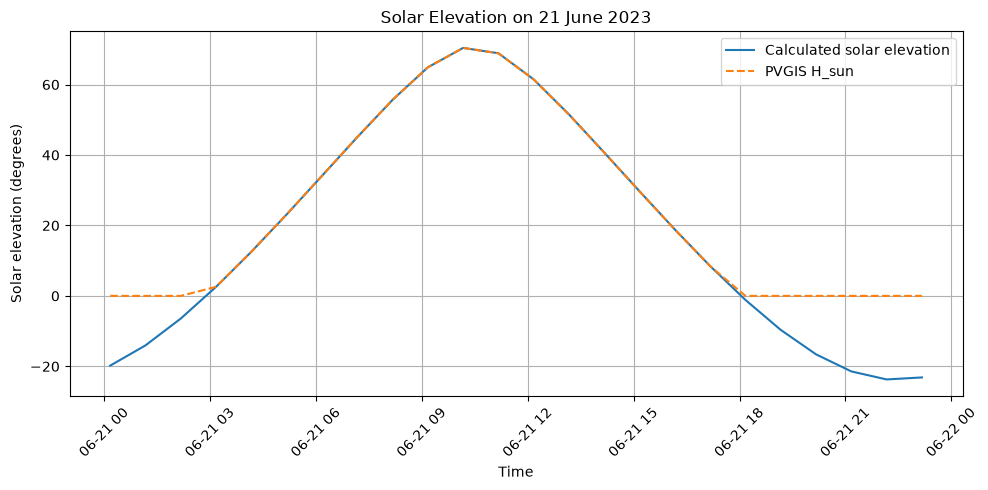

In [18]:
# Plot solar elevation during the selected day
plt.figure(figsize=(10, 5))

plt.plot(day_table["time"], day_table["solar_elevation"],
         label="Calculated solar elevation")

plt.plot(day_table["time"], day_table["H_sun"],
         label="PVGIS H_sun", linestyle="--")

plt.xlabel("Time")
plt.ylabel("Solar elevation (degrees)")
plt.title("Solar Elevation on 21 June 2023")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The angle of incidence is the angle between the incoming sunlight and the normal line of the solar panel. The angle of incidence is important because a solar panel receives the most direct sunlight when the Sun's rays are perpendicular to its surface.

If the angle of incidence is $0^\circ$, sunlight hits the panel directly.

If the angle is $60^\circ$, sunlight hits the panel at an angle.

If the angle is greater than $90^\circ$, the Sun is behind the panel and the panel does not receive direct sunlight.

I'l use the following formula:

$\cos(\theta_i) = \cos(\theta_z)\cos(\beta) + \sin(\theta_z)\sin(\beta)\cos(A_s - A_p)$

Where:
$\theta_i$ is the angle of incidence;
$\theta_z$ is the solar zenith angle;
$\beta$ is the panel tilt angle;
$A_s$ is the solar azimuth;
$A_p$ is the panel azimuth.
My panel faces south, so:

$A_p = 180^\circ$

Remember that my azimuth is measured clockwise from north:
North = $0^\circ$
East = $90^\circ$
South = $180^\circ$
West = $270^\circ$
I can calculate the solar zenith angle using the solar elevation:

$\theta_z = 90^\circ - \alpha_s$

Where $\alpha_s$ is the solar elevation calculated previously.

After calculating the cosine of the incidence angle, I calculate the angle itself:

$\theta_i = \arccos(\cos(\theta_i))$

I must also make sure that the cosine value is between -1 and 1. If the Sun is behind the panel, the direct contribution is zero.

In [ ]:
# Panel azimuth: south
panel_azimuth = 180

# Convert solar position data to NumPy arrays
solar_elevation_array = np.asarray(solar_elevation)
solar_azimuth_array = np.asarray(solar_azimuth)

# Calculate solar zenith angle
solar_zenith = 90 - solar_elevation_array

# Convert angles to radians
solar_zenith_rad = np.radians(solar_zenith)
solar_azimuth_rad = np.radians(solar_azimuth_array)
panel_azimuth_rad = np.radians(panel_azimuth)

tilt_rad = np.radians(tilt_angles)

# Calculate the cosine of the incidence angle
cos_incidence = (
    np.cos(solar_zenith_rad)[np.newaxis, :]
    * np.cos(tilt_rad)[:, np.newaxis]
    +
    np.sin(solar_zenith_rad)[np.newaxis, :]
    * np.sin(tilt_rad)[:, np.newaxis]
    * np.cos(
        solar_azimuth_rad - panel_azimuth_rad
    )[np.newaxis, :]
)

# Keep cosine values between -1 and 1
cos_incidence = np.clip(cos_incidence, -1, 1)

# Calculate the incidence angle in degrees
incidence_angle = np.degrees(
    np.arccos(cos_incidence)
)

In [ ]:
# Find the index for a 32-degree tilt
tilt_32_index = np.where(tilt_angles == 32)[0][0]

# Get incidence angles for this tilt
incidence_32 = incidence_angle[tilt_32_index]
noon_index = np.argmax(solar_elevation)

Direct solar radiation is the sunlight that comes directly from the Sun to the solar panel. I''ll use the received angle to calculate how much direct solar radiation reaches the tilted panel. The original PVGIS data contains direct solar radiation on a horizontal surface. I need to convert it to direct radiation on a tilted surface. The main idea is simple:

When sunlight is perpendicular to the panel, the panel receives more direct radiation.

When sunlight arrives at a large angle, the panel receives less direct radiation.

When the Sun is behind the panel, direct radiation is zero.

The direct radiation on a tilted panel is calculated using the following formula:

$$
G_{b,\text{tilt}} = DNI \cdot \max(0, \cos(\theta_i))
$$

Where:
G_b_tilt is direct solar radiation on the tilted panel, in W/m²;
DNI is direct normal irradiance, in W/m²;
theta_i is the angle of incidence calculated in Part 5.
What is DNI?

DNI (Direct Normal Irradiance) is the amount of direct solar radiation measured on a surface perpendicular to the Sun's rays. I can calculate DNI from the direct radiation on a horizontal surface:

$$
DNI = \frac{G_{b,\text{horizontal}}}{\cos(\theta_z)}
$$

Where:
G_b_horizontal is direct solar radiation on a horizontal surface, from the PVGIS column Gb(i);
theta_z is the solar zenith angle.

$$
G_{b,\text{tilt}} = \frac{G_{b,\text{horizontal}} \cdot \max(0, \cos(\theta_i))}{\cos(\theta_z)}
$$

Division by a very small number can produce unrealistically large values, so I'll use the formula only when:

$ cos(theta_z) > 0.065 $

This means that the Sun must be more than approximately 3.7 degrees above the horizon. Otherwise, I set direct radiation to zero.

In [ ]:
# Get direct radiation on a horizontal surface
direct_horizontal = data["Gb(i)"].to_numpy()

# Create a mask for hours when the Sun is sufficiently high
valid_sun = cos_zenith > 0.065

# Calculate direct normal irradiance
dni = np.zeros(len(data))

dni[valid_sun] = (
    direct_horizontal[valid_sun]
    / cos_zenith[valid_sun]
)

# Calculate direct radiation on the tilted panel
direct_tilted = (
    np.maximum(cos_incidence, 0)
    * dni[np.newaxis, :]
)
tilt_32_index = np.where(tilt_angles == 32)[0][0]
direct_32 = direct_tilted[tilt_32_index]
max_direct = np.max(direct_32)


Diffuse solar radiation is sunlight that is scattered by clouds, dust, and molecules in the atmosphere. Even when the Sun is behind a cloud, the solar panel can still receive diffuse radiation.So I''l use a simple isotropic sky model. This model assumes that diffuse radiation is distributed evenly across the sky.

For an isotropic sky, diffuse radiation on a tilted panel is calculated using the following formula:

$$
\text{Diffuse radiation on a tilted panel} = G_d \times \frac{1 + \cos(\beta)}{2}
$$

Where:
 $G_d$ is diffuse solar radiation on a horizontal surface, in $\mathrm{W/m^2}$.
$\beta$ is the tilt angle of the solar panel.
$\dfrac{1 + \cos(\beta)}{2}$ is the sky view factor.

For a horizontal panel ($\beta = 0^\circ$), the factor is $1$. This means the panel receives diffuse radiation from the whole sky.

For a vertical panel ($\beta = 90^\circ$), the factor is $0.5$. This means the panel receives diffuse radiation from half of the sky. I'll use the $G_d(i)$ column from the dataset as diffuse radiation on a horizontal surface.

In [ ]:
# Get diffuse radiation on a horizontal surface
diffuse_horizontal = data["Gd(i)"].to_numpy()

# Calculate the sky view factor for each tilt angle
sky_view_factor = (1 + np.cos(tilt_rad)) / 2

# Calculate diffuse radiation on tilted panels
diffuse_tilted = (
    sky_view_factor[:, np.newaxis]
    * diffuse_horizontal[np.newaxis, :]
)
diffuse_32 = diffuse_tilted[tilt_32_index]
horizontal_index = np.where(tilt_angles == 0)[0][0]
vertical_index = np.where(tilt_angles == 90)[0][0]


Solar radiation can also reach the panel after being reflected from the ground. The amount of reflected radiation depends on:

The solar radiation reaching the ground.

The ground reflectivity (albedo).

The tilt angle of the solar panel.
In the project, I assume that the ground has an albedo of 0.20.

Ground-reflected radiation:
$$
G_{r,\text{tilted}} =
\rho \cdot GHI \cdot \frac{1-\cos(\beta)}{2}
$$

$ G_{r,\text{tilted}}$ is ground-reflected radiation on the tilted panel, in W/m².
$ \rho$ is the ground albedo.
$ GHI $ is global horizontal irradiance, in W/m².
$ \beta$ is the tilt angle of the solar panel.
$ \frac{1-\cos(\beta)}{2} $ is the ground view factor.
Global horizontal irradiance:
$$
GHI = G_b + G_d
$$

$ G_b $ is direct solar radiation on a horizontal surface.
$ G_d $ is diffuse solar radiation on a horizontal surface.
For a horizontal panel $ (\beta = 0^\circ$), the ground view factor is 0. 
For a vertical panel $(\beta = 90^\circ$), the ground view factor is 0.5.

In [ ]:
# Calculate global horizontal irradiance
ghi = direct_horizontal + diffuse_horizontal

# Calculate the ground view factor for each tilt angle
ground_view_factor = (1 - np.cos(tilt_rad)) / 2

# Calculate ground-reflected radiation on tilted panels
ground_reflected_tilted = (
    ground_albedo
    * ghi[np.newaxis, :]
    * ground_view_factor[:, np.newaxis]
)
ground_reflected_32 = ground_reflected_tilted[tilt_32_index]

A tilted solar panel receives solar radiation from three main sources:

Direct radiation — sunlight coming directly from the Sun.

Diffuse radiation — sunlight scattered by clouds and the atmosphere.

Ground-reflected radiation — sunlight reflected from the ground.

The total solar radiation on a tilted panel is the sum of direct, diffuse, and ground-reflected radiation:
$$
G_{\text{total}} =
G_{\text{direct}} +
G_{\text{diffuse}} +
G_{\text{reflected}}
$$

Where:
$ G_{\text{total}}$ is total solar radiation on the tilted panel, in W/m².
$ G_{\text{direct}}$ is direct solar radiation on the tilted panel.
$ G_{\text{diffuse}}$ is diffuse solar radiation on the tilted panel.
$ G_{\text{reflected}}$ is ground-reflected solar radiation on the tilted panel.

In [ ]:
# Calculate total solar radiation on tilted panels
total_tilted = (
    direct_tilted
    + diffuse_tilted
    + ground_reflected_tilted
)
total_32 = total_tilted[tilt_32_index]
max_total = np.max(total_32)

**Part 3. Panel Temperature: NOCT and Faiman models. Electrical efficiency and energy.**

The panel temperature depends on:

Ambient air temperature.

Solar radiation intensity.

Panel characteristics.

In this part, I use the NOCT (Nominal Operating Cell Temperature) model to estimate the panel temperature.

NOCT is the temperature reached by a solar cell under standard reference conditions:

Solar radiation: 800 W/m².

Ambient temperature: 20°C.

Wind speed: 1 m/s.

The panel temperature is estimated using the following formula:
$$
T_{\text{panel}} =
T_{\text{air}} +
\frac{G_{\text{total}}}{800}
\cdot (NOCT - 20)
$$

Where:
$ T_{\text{panel}}$ is the estimated panel temperature, in °C.
$ T_{\text{air}}$ is the ambient air temperature, in °C.
$ G_{\text{total}}$ is total solar radiation on the tilted panel, in W/m².
$ NOCT $ is the Nominal Operating Cell Temperature, in °C.
800 W/m² is the reference solar radiation level.
20°C is the reference ambient temperature.
NOCT value of 45°C in this project.

In [ ]:
# Get ambient air temperature
air_temperature = data["T2m"].to_numpy()

# Calculate panel temperature using the NOCT model
panel_temperature_noct = (
    air_temperature[np.newaxis, :]
    + (total_tilted / 800) * (NOCT - 20)
)
temperature_noct_32 = panel_temperature_noct[tilt_32_index]
max_temperature_noct = np.max(temperature_noct_32)


The Faiman model estimates the operating temperature of a solar panel. Unlike the NOCT model, it also considers wind speed.Wind helps cool the solar panel and higher wind speed usually results in a lower panel temperature.

Wind speed is taken from the WS10m column of our dataset. It represents wind speed at 10 metres above the ground, so I use it as an approximation of wind speed near the panel. The Faiman model calculates panel temperature next:
$$
T_{\text{panel}} =
T_{\text{air}} +
\frac{G_{\text{total}}}{U_0 + U_1 \cdot v}
$$

$ T_{\text{panel}}$ is the panel temperature, in °C.
$ T_{\text{air}}$ is the ambient air temperature, in °C.
$G_{\text{total}}$ is total solar radiation on the panel, in W/m².
$ U_0 $ and $ U_1 $ are heat loss coefficients.
$ v $ is wind speed, in m/s.
$ U_0 = 25 $
$ U_1 = 6.84 $

In [ ]:
# Get wind speed from the dataset
wind_speed = data["WS10m"].to_numpy()

# Prevent negative wind speed values
wind_speed = np.maximum(wind_speed, 0)

# Calculate panel temperature using the Faiman model
panel_temperature_faiman = (
    air_temperature[np.newaxis, :]
    + total_tilted
    / (
        U0
        + U1 * wind_speed[np.newaxis, :]
    )
)
temperature_faiman_32 = panel_temperature_faiman[tilt_32_index]
max_temperature_faiman = np.max(temperature_faiman_32)

The temperature-dependent electrical efficiency is calculated using:
$$
\eta =
\eta_0 \cdot
\left[1-\gamma \cdot (T_{\text{panel}}-25)\right]
$$

This correction is applied when the panel temperature is above 25°C. When the temperature is 25°C or lower, nominal efficiency is used.

$\eta$ is the electrical efficiency of the panel.
$\eta_0$ is the nominal electrical efficiency.
$\gamma$ is the temperature coefficient.
$ T_{\text{panel}}$ is the panel temperature, in °C.
25°C is the reference temperature.
Electrical energy produced during one time interval is calculated using:
$$
E = G_{\text{total}} \cdot A \cdot \eta \cdot \Delta t
$$

$E$ is electrical energy, in Wh.
$G_{\text{total}}$ is total solar radiation, in W/m².
$A$ is panel area, in m².
$\eta$ is electrical efficiency.
$\Delta t$ is the time interval, in hours.
Total annual energy is calculated by adding the energy produced during all time intervals.

In [ ]:
# Calculate energy without temperature correction
energy_no_temperature = (
    total_tilted
    * panel_area
    * nominal_efficiency
    * dt_hours
)

# Calculate annual energy in kWh for each tilt angle
annual_energy_no_temperature = (
    np.sum(energy_no_temperature, axis=1) / 1000
)

In [ ]:
# Calculate electrical efficiency using NOCT temperature
efficiency_noct = nominal_efficiency * (
    1 - temperature_coefficient
    * np.maximum(panel_temperature_noct - 25, 0)
)

# Keep efficiency within valid limits
efficiency_noct = np.clip(
    efficiency_noct,
    0,
    nominal_efficiency
)

# Calculate electrical energy using NOCT
energy_noct = (
    total_tilted
    * panel_area
    * efficiency_noct
    * dt_hours
)

# Calculate annual energy in kWh
annual_energy_noct = (
    np.sum(energy_noct, axis=1) / 1000
)

In [ ]:
# Calculate electrical efficiency using Faiman temperature
efficiency_faiman = nominal_efficiency * (
    1 - temperature_coefficient
    * np.maximum(panel_temperature_faiman - 25, 0)
)

# Keep efficiency within valid limits
efficiency_faiman = np.clip(
    efficiency_faiman,
    0,
    nominal_efficiency
)

# Calculate electrical energy using Faiman
energy_faiman = (
    total_tilted
    * panel_area
    * efficiency_faiman
    * dt_hours
)

# Calculate annual energy in kWh
annual_energy_faiman = (
    np.sum(energy_faiman, axis=1) / 1000
)

In [ ]:
print(
    "Annual energy without temperature correction:",
    round(annual_energy_no_temperature[tilt_32_index], 2),
    "kWh"
)

print(
    "Annual energy using NOCT:",
    round(annual_energy_noct[tilt_32_index], 2),
    "kWh"
)

print(
    "Annual energy using Faiman:",
    round(annual_energy_faiman[tilt_32_index], 2),
    "kWh"
)

In [ ]:
print(
    "Nominal efficiency:",
    round(nominal_efficiency * 100, 2),
    "%"
)

print(
    "Average NOCT efficiency:",
    round(np.mean(efficiency_noct[tilt_32_index]) * 100, 2),
    "%"
)

print(
    "Average Faiman efficiency:",
    round(np.mean(efficiency_faiman[tilt_32_index]) * 100, 2),
    "%"
)

Part 13. Tilt angle optimization

The optimal tilt angle is the angle that produces the highest annual electrical energy.I''ll compare three scenarios:

1.Without temperature correction.

2.Using the NOCT temperature model.

3.Using the Faiman temperature model.

For each scenario, Il find the tilt angle with the maximum annual energy production.

$$
\beta_{\text{optimal}} =
\underset{\beta}{\operatorname{argmax}}
\ E_{\text{annual}}(\beta)
$$

Where:
$\beta_{\text{optimal}}$ is the optimal panel tilt angle.
$\beta$ is the panel tilt angle.
$ E_{\text{annual}}(\beta)$ is the annual electrical energy produced at a given tilt angle.
I evaluate tilt angles from 0° to 90° in steps of 0.5°.

In [ ]:
# Find the index of maximum annual energy for each scenario
best_index_no_temperature = np.argmax(
    annual_energy_no_temperature
)

best_index_noct = np.argmax(
    annual_energy_noct
)

best_index_faiman = np.argmax(
    annual_energy_faiman
)

# Get the optimal tilt angles
best_tilt_no_temperature = tilt_angles[
    best_index_no_temperature
]

best_tilt_noct = tilt_angles[
    best_index_noct
]

best_tilt_faiman = tilt_angles[
    best_index_faiman
]

# Get the maximum annual energy values
best_energy_no_temperature = annual_energy_no_temperature[
    best_index_no_temperature
]

best_energy_noct = annual_energy_noct[
    best_index_noct
]

best_energy_faiman = annual_energy_faiman[
    best_index_faiman
]

print("Optimal tilt angle without temperature correction:",
      best_tilt_no_temperature, "degrees")

print("Optimal tilt angle using NOCT:",
      best_tilt_noct, "degrees")

print("Optimal tilt angle using Faiman:",
      best_tilt_faiman, "degrees")

print()

print("Maximum annual energy without temperature correction:",
      round(best_energy_no_temperature, 2), "kWh")

print("Maximum annual energy using NOCT:",
      round(best_energy_noct, 2), "kWh")

print("Maximum annual energy using Faiman:",
      round(best_energy_faiman, 2), "kWh")

In [ ]:
optimization_results = pd.DataFrame({
    "Scenario": [
        "Without temperature correction",
        "NOCT",
        "Faiman"
    ],
    "Optimal tilt angle (degrees)": [
        best_tilt_no_temperature,
        best_tilt_noct,
        best_tilt_faiman
    ],
    "Annual energy (kWh)": [
        best_energy_no_temperature,
        best_energy_noct,
        best_energy_faiman
    ]
})

display(optimization_results)

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    tilt_angles,
    annual_energy_no_temperature,
    label="Without temperature correction"
)

plt.plot(
    tilt_angles,
    annual_energy_noct,
    label="NOCT"
)

plt.plot(
    tilt_angles,
    annual_energy_faiman,
    label="Faiman"
)

plt.xlabel("Panel tilt angle (degrees)")
plt.ylabel("Annual energy production (kWh)")
plt.title("Annual Energy Production vs Panel Tilt Angle")

plt.legend()
plt.grid(True)

plt.show()

**Conclusion**

The dataset contained 8,760 hourly measurements covering the whole year. For a panel tilted at 32 degrees, the estimated annual energy production was:

507.95 kWh without temperature correction.

484.44 kWh using the NOCT model.

488.10 kWh using the Faiman model.

The results show that temperature has a noticeable effect on energy production. Compared with the model without temperature correction, annual energy production decreased by approximately 4.63% with NOCT and 3.91% with Faiman.

The maximum estimated panel temperatures were 62.74°C for NOCT and 63.98°C for Faiman. These results demonstrate why temperature should be considered when estimating solar panel performance.


This project demonstrates how numerical methods and real weather data can be used to estimate solar panel performance and investigate the influence of environmental conditions.

The results confirm that panel temperature reduces electrical efficiency and annual energy production. The NOCT and Faiman models provide different estimates because they describe panel heating and cooling in different ways.

The final optimization compares all tested tilt angles to identify the angle that produces the highest annual energy output in Sofia. This provides a useful estimate for selecting the tilt angle of a fixed, south-facing solar panel.

Overall, the project combines solar geometry, numerical calculations, data analysis, and optimization to show how mathematical models can support practical decisions in renewable energy systems.

In [ ]:

scenarios = [
    "Without temperature correction",
    "NOCT",
    "Faiman"
]

energy_values = [
    best_energy_no_temperature,
    best_energy_noct,
    best_energy_faiman
]

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    scenarios,
    energy_values
)

# Add values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 3,
        f"{height:.2f} kWh",
        ha="center"
    )

# Add chart title and axis labels
plt.title("Annual Energy Production Comparison")
plt.xlabel("Scenario")
plt.ylabel("Annual Energy Production (kWh)")

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.ylim(0, max(energy_values) * 1.15)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**References:**
1. European Commission — PVGIS (Photovoltaic Geographical Information System) -     https://re.jrc.ec.europa.eu/pvg_tools/en/tools.html
https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis/general-information/data-sources-calculation-methods_en
3. NOAA — General Solar Position Calculations - https://gml.noaa.gov/grad/solcalc/solareqns.PDF
4. NASA POWER: Tilted Surface Radiation Methodology - https://ntrs.nasa.gov/api/citations/20220000423/downloads/2022%20NASA%20LaRC%20POWER%20AMS%20Presentation%20(Paola%20Holleway)-2_pws.pdf
https://power.larc.nasa.gov/docs/methodology/data/derived/tilted-surfaces
6. Sandia sources used for NOCT model, Faiman and isoptoric sky diffusion:
   a) https://pvpmc.sandia.gov/modeling-guide/1-weather-design-inputs/plane-of-array-poa-irradiance/calculating-poa-irradiance/poa-sky-diffuse/isotropic-sky-diffuse-model/
   b) https://pvpmc.sandia.gov/modeling-guide/1-weather-design-inputs/plane-of-array-poa-irradiance/calculating-poa-irradiance/poa-ground-reflected/albedo/
   c) https://pvpmc.sandia.gov/modeling-guide/2-dc-module-iv/cell-temperature/noct-cell-temperature/
   d) https://pvpmc.sandia.gov/modeling-guide/2-dc-module-iv/module-temperature/faiman-module-temperature-model/
   e) https://pvpmc.sandia.gov/modeling-guide/5-ac-system-output/pv-performance-metrics/normalized-efficiency/
8. PVsyst: Albedo Usual Coefficients - https://www.pvsyst.com/help/physical-models-used/irradiation-models/albedo-usual-coefficients.html